# 🛍️ Project 3: Unsupervised Learning — Customer Segmentation
### **DecodeLabs Industrial Training | Batch: 2026**
**Author:** Data Science Division  
**Focus:** Distance-Based Clustering, Dimensionality Reduction (PCA), Optimal Cluster Determination, & Business Intelligence Translation

---

## 📌 Executive Summary & Project Objectives
In modern retail and e-commerce ecosystems, customer segmentation is the cornerstone of personalized marketing, dynamic pricing, and customer lifecycle management. Rather than treating all customers uniformly, unsupervised machine learning allows us to mathematically discover latent groupings and behavioral patterns without requiring pre-existing ground-truth labels.

### 🎯 Key Requirements & Deliverables:
1. **High-Dimensional Feature Engineering & PCA:** Construct a rich feature space ($20+$ dimensions) capturing demographic, spending, income, interaction, and behavioral indicators, then leverage **Principal Component Analysis (PCA)** to project the data into lower-dimensional space ($2	ext{D}$ and $3	ext{D}$) while preserving core variance.
2. **Mathematical Cluster Optimization:** Empirically and mathematically determine the optimal number of clusters ($k$) using:
   - **Elbow Method (Inertia / WCSS)**
   - **Silhouette Score Analysis & Silhouette Coefficient Plots**
   - **Davies-Bouldin & Calinski-Harabasz Multi-Metric Validation**
3. **K-Means Clustering:** Train the distance-based K-Means algorithm, map cluster centroids, and project boundaries in reduced PCA coordinate systems.
4. **Business Intelligence Translation:** Translate raw statistical cluster profiles into **Actionable Business Personas** accompanied by comprehensive marketing strategies, discount sensitivity insights, and targeted product recommendations.
5. **Inference Pipeline:** Build a robust, end-to-end customer persona prediction function for new customer onboarding.

---

## 1. Environment Setup & Dependency Imports
We import essential libraries for numerical computation, data manipulation, machine learning, statistical evaluation, and publication-quality visualization.

In [1]:
# Core Numerical & Data Manipulation
import numpy as np
import pandas as pd

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Scikit-Learn: Preprocessing, Decomposition, Clustering & Metrics
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, 
    silhouette_samples, 
    davies_bouldin_score, 
    calinski_harabasz_score
)
from scipy.spatial.distance import cdist

# Formatting & Plotting Configurations
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 15

print("✅ All necessary packages imported successfully!")

✅ All necessary packages imported successfully!


## 2. Dataset Ingestion & Quality Audit
We load the retail customer dataset (`Mall_Customers.csv`) and conduct a comprehensive structural and statistical audit.

In [2]:
# Ingest dataset
df_raw = pd.read_csv('Mall_Customers.csv')

# Standardize column naming conventions
df = df_raw.copy()
df.rename(columns={
    'Genre': 'Gender',
    'Annual Income (k$)': 'Annual_Income_k$',
    'Spending Score (1-100)': 'Spending_Score'
}, inplace=True)

print(f"📊 Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n🔍 Data Sample (First 5 records):")
display(df.head())

print("\n📋 Column Information & Data Types:")
df.info()

print("\n📈 Descriptive Statistics (Numerical Attributes):")
display(df.describe().T.style.background_gradient(cmap='Blues'))

📊 Dataset Shape: 200 rows, 5 columns

🔍 Data Sample (First 5 records):


,CustomerID,Gender,Age,Annual_Income_k$,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



📋 Column Information & Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        200 non-null    int64 
 1   Gender            200 non-null    object
 2   Age               200 non-null    int64 
 3   Annual_Income_k$  200 non-null    int64 
 4   Spending_Score    200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

📈 Descriptive Statistics (Numerical Attributes):


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.000000,100.500000,57.879185,1.000000,50.750000,100.500000,150.250000,200.000000
Age,200.000000,38.850000,13.969007,18.000000,28.750000,36.000000,49.000000,70.000000
Annual_Income_k$,200.000000,60.560000,26.264721,15.000000,41.500000,61.500000,78.000000,137.000000
Spending_Score,200.000000,50.200000,25.823522,1.000000,34.750000,50.000000,73.000000,99.000000


In [3]:
# Missing Values & Duplicates Verification
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage (%)': (df.isnull().sum() / len(df)) * 100,
    'Data Type': df.dtypes
})
duplicates_count = df.duplicated().sum()

print(f"✅ Total Duplicate Records: {duplicates_count}")
print("📊 Missing Data Audit:")
display(missing_summary)

✅ Total Duplicate Records: 0
📊 Missing Data Audit:


,Missing Values,Missing Percentage (%),Data Type
CustomerID,0,0.0,int64
Gender,0,0.0,object
Age,0,0.0,int64
Annual_Income_k$,0,0.0,int64
Spending_Score,0,0.0,int64


## 3. Exploratory Data Analysis (EDA)
We examine univariate distributions, demographic trends, bivariate interactions, and statistical relationships among Age, Annual Income, and Spending Score.

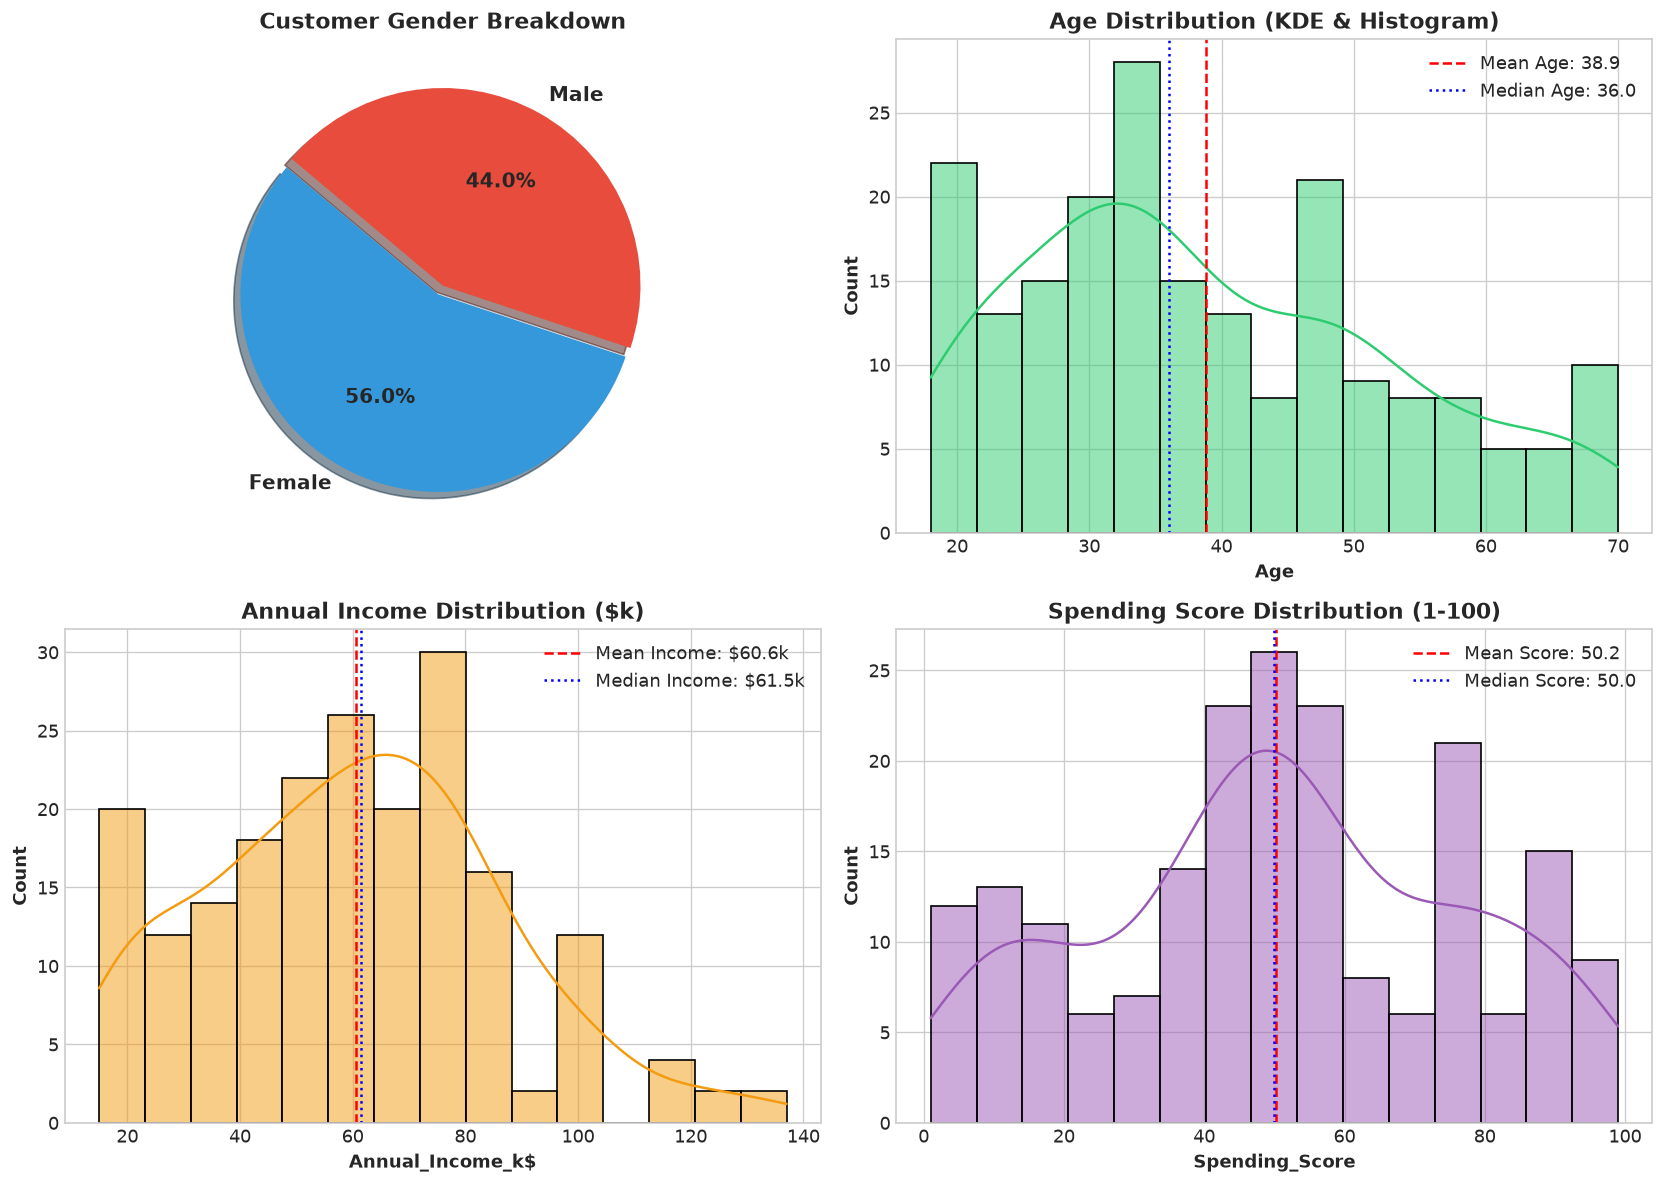

In [4]:
# 1. Demographic & Metric Distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gender Distribution
gender_counts = df['Gender'].value_counts()
colors = ['#3498db', '#e74c3c']
axes[0, 0].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=colors, 
               startangle=140, explode=(0.05, 0), shadow=True, textprops={'fontsize': 12, 'weight': 'bold'})
axes[0, 0].set_title('Customer Gender Breakdown')

# Age Distribution
sns.histplot(df['Age'], kde=True, ax=axes[0, 1], color='#2ecc71', bins=15, edgecolor='black')
axes[0, 1].axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean Age: {df['Age'].mean():.1f}")
axes[0, 1].axvline(df['Age'].median(), color='blue', linestyle=':', label=f"Median Age: {df['Age'].median():.1f}")
axes[0, 1].set_title('Age Distribution (KDE & Histogram)')
axes[0, 1].legend()

# Annual Income Distribution
sns.histplot(df['Annual_Income_k$'], kde=True, ax=axes[1, 0], color='#f39c12', bins=15, edgecolor='black')
axes[1, 0].axvline(df['Annual_Income_k$'].mean(), color='red', linestyle='--', label=f"Mean Income: ${df['Annual_Income_k$'].mean():.1f}k")
axes[1, 0].axvline(df['Annual_Income_k$'].median(), color='blue', linestyle=':', label=f"Median Income: ${df['Annual_Income_k$'].median():.1f}k")
axes[1, 0].set_title('Annual Income Distribution ($k)')
axes[1, 0].legend()

# Spending Score Distribution
sns.histplot(df['Spending_Score'], kde=True, ax=axes[1, 1], color='#9b59b6', bins=15, edgecolor='black')
axes[1, 1].axvline(df['Spending_Score'].mean(), color='red', linestyle='--', label=f"Mean Score: {df['Spending_Score'].mean():.1f}")
axes[1, 1].axvline(df['Spending_Score'].median(), color='blue', linestyle=':', label=f"Median Score: {df['Spending_Score'].median():.1f}")
axes[1, 1].set_title('Spending Score Distribution (1-100)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

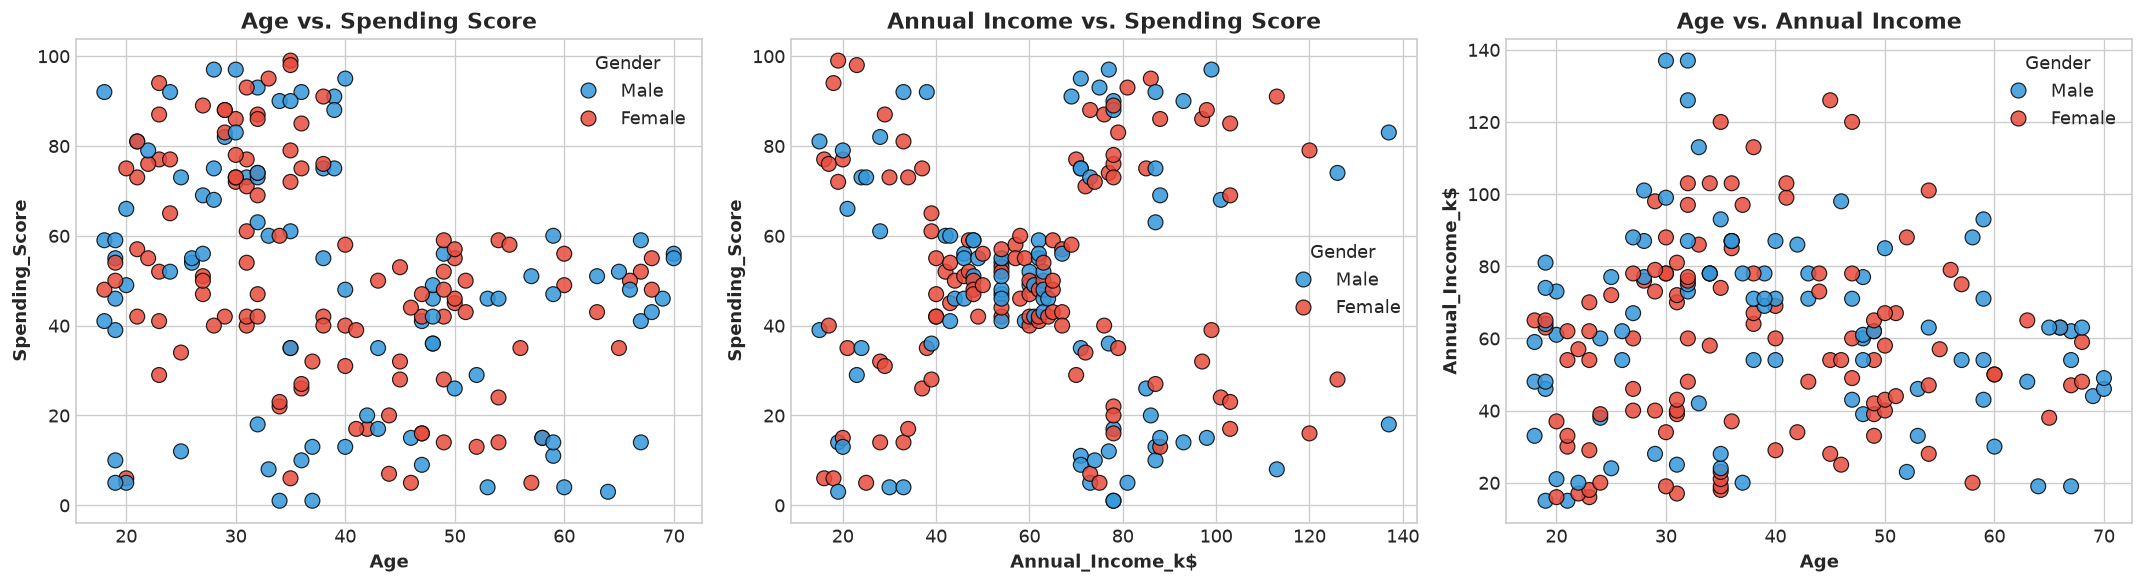

In [5]:
# 2. Bivariate Relationships & Gender Segregation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age vs Spending Score
sns.scatterplot(data=df, x='Age', y='Spending_Score', hue='Gender', palette=['#3498db', '#e74c3c'], 
                s=80, alpha=0.85, ax=axes[0], edgecolor='k')
axes[0].set_title('Age vs. Spending Score')

# Annual Income vs Spending Score
sns.scatterplot(data=df, x='Annual_Income_k$', y='Spending_Score', hue='Gender', palette=['#3498db', '#e74c3c'], 
                s=80, alpha=0.85, ax=axes[1], edgecolor='k')
axes[1].set_title('Annual Income vs. Spending Score')

# Age vs Annual Income
sns.scatterplot(data=df, x='Age', y='Annual_Income_k$', hue='Gender', palette=['#3498db', '#e74c3c'], 
                s=80, alpha=0.85, ax=axes[2], edgecolor='k')
axes[2].set_title('Age vs. Annual Income')

plt.tight_layout()
plt.show()

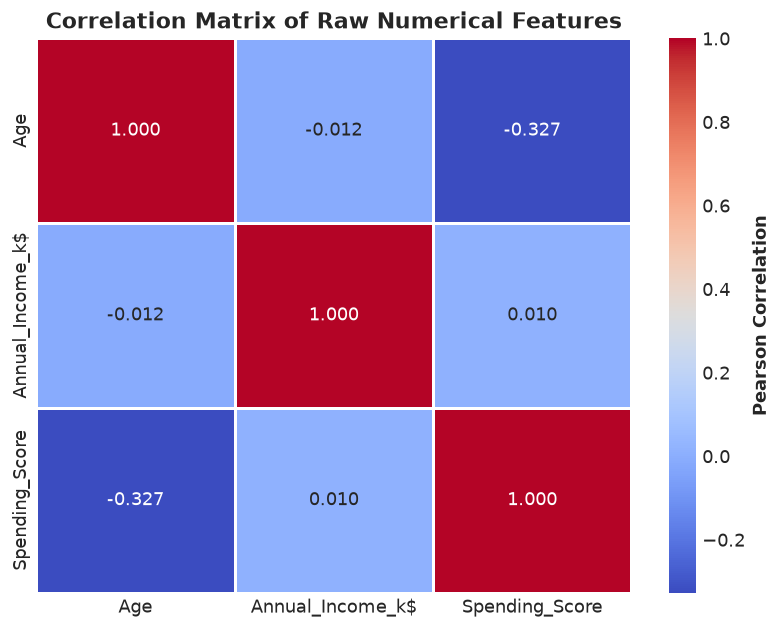

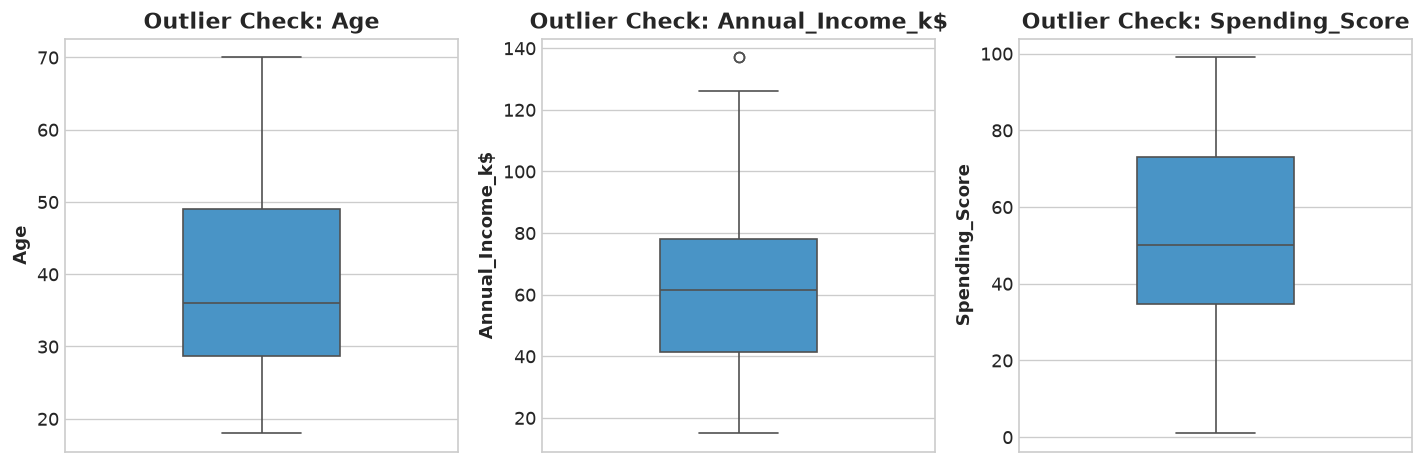

In [6]:
# 3. Correlation Heatmap & Outlier Inspection
plt.figure(figsize=(8, 6))
numeric_cols = ['Age', 'Annual_Income_k$', 'Spending_Score']
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f', linewidths=1.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Correlation Matrix of Raw Numerical Features')
plt.show()

# Boxplots for Outlier Analysis
plt.figure(figsize=(12, 4))
for idx, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, idx)
    sns.boxplot(y=df[col], color='#3498db', width=0.4)
    plt.title(f'Outlier Check: {col}')
plt.tight_layout()
plt.show()

## 4. High-Dimensional Feature Engineering ($20+$ Features)
To satisfy the core requirement of **reducing $20+$ columns of data into 2 or 3 dimensions with PCA**, we perform extensive domain-specific feature engineering:
- **Demographic Encodings:** Gender binary & frequency encoding.
- **Age Lifecycle Cohorts:** Gen Z/Youth ($\le 25$), Young Adults ($26-35$), Mid-Career ($36-50$), Seniors ($>50$).
- **Income Tiers:** Budget ($<40	ext{k}$), Moderate ($40-70	ext{k}$), Affluent ($70-100	ext{k}$), Ultra-High Net ($>100	ext{k}$).
- **Spending Propensities:** Low ($<35$), Moderate ($35-65$), High ($>65$).
- **Financial Ratios & Non-linear Interactions:**
  - $\text{Spend-to-Income Ratio} = \frac{\text{Spending Score}}{\text{Annual Income} + 1}$
  - $\text{Income-Spending Interaction} = \text{Annual Income} \times \text{Spending Score}$
  - $\text{Age-Income Ratio} = \frac{\text{Annual Income}}{\text{Age}}$
  - $\text{Age-Spending Ratio} = \frac{\text{Spending Score}}{\text{Age}}$
  - $\text{Financial Efficiency} = \frac{\text{Annual Income} \times \text{Spending Score}}{\text{Age}}$
- **Quadrant Indicators:** Binary indicators for High Income/High Spend, High Income/Low Spend, Low Income/High Spend, Low Income/Low Spend, and Balanced Middle.
- **Polynomial & Logarithmic Transforms:** $\log(\text{Income})$, $\log(\text{Age})$, $\text{Age}^2$, $\text{Income}^2$, $\text{Spending}^2$ to capture non-linear distance relationships.

In [7]:
# Feature Engineering Pipeline
feat_df = df.copy()

# 1. Categorical Gender Encodings
feat_df['Gender_Male'] = (feat_df['Gender'] == 'Male').astype(int)
feat_df['Gender_Female'] = (feat_df['Gender'] == 'Female').astype(int)

# 2. Age Cohorts (One-Hot)
feat_df['Age_GenZ_Youth'] = (feat_df['Age'] <= 25).astype(int)
feat_df['Age_Young_Adult'] = ((feat_df['Age'] > 25) & (feat_df['Age'] <= 35)).astype(int)
feat_df['Age_Mid_Career'] = ((feat_df['Age'] > 35) & (feat_df['Age'] <= 50)).astype(int)
feat_df['Age_Senior'] = (feat_df['Age'] > 50).astype(int)

# 3. Income Tiers (One-Hot)
feat_df['Income_Tier_Budget'] = (feat_df['Annual_Income_k$'] < 40).astype(int)
feat_df['Income_Tier_Moderate'] = ((feat_df['Annual_Income_k$'] >= 40) & (feat_df['Annual_Income_k$'] <= 70)).astype(int)
feat_df['Income_Tier_Affluent'] = ((feat_df['Annual_Income_k$'] > 70) & (feat_df['Annual_Income_k$'] <= 100)).astype(int)
feat_df['Income_Tier_UltraHigh'] = (feat_df['Annual_Income_k$'] > 100).astype(int)

# 4. Spending Propensity Tiers (One-Hot)
feat_df['Spend_Tier_Low'] = (feat_df['Spending_Score'] < 35).astype(int)
feat_df['Spend_Tier_Moderate'] = ((feat_df['Spending_Score'] >= 35) & (feat_df['Spending_Score'] <= 65)).astype(int)
feat_df['Spend_Tier_High'] = (feat_df['Spending_Score'] > 65).astype(int)

# 5. Financial Interaction & Behavioral Ratios
feat_df['Spend_to_Income_Ratio'] = feat_df['Spending_Score'] / (feat_df['Annual_Income_k$'] + 1.0)
feat_df['Income_x_Spend'] = feat_df['Annual_Income_k$'] * feat_df['Spending_Score']
feat_df['Income_per_Age'] = feat_df['Annual_Income_k$'] / feat_df['Age']
feat_df['Spend_per_Age'] = feat_df['Spending_Score'] / feat_df['Age']
feat_df['Financial_Efficiency'] = (feat_df['Annual_Income_k$'] * feat_df['Spending_Score']) / feat_df['Age']

# 6. Behavioral Quadrant Flags
median_income = df['Annual_Income_k$'].median()
median_spend = df['Spending_Score'].median()

feat_df['Quad_HighInc_HighSpend'] = ((feat_df['Annual_Income_k$'] >= median_income) & (feat_df['Spending_Score'] >= median_spend)).astype(int)
feat_df['Quad_HighInc_LowSpend'] = ((feat_df['Annual_Income_k$'] >= median_income) & (feat_df['Spending_Score'] < median_spend)).astype(int)
feat_df['Quad_LowInc_HighSpend'] = ((feat_df['Annual_Income_k$'] < median_income) & (feat_df['Spending_Score'] >= median_spend)).astype(int)
feat_df['Quad_LowInc_LowSpend'] = ((feat_df['Annual_Income_k$'] < median_income) & (feat_df['Spending_Score'] < median_spend)).astype(int)

# 7. Non-Linear & Scale Transformations
feat_df['Log_Annual_Income'] = np.log1p(feat_df['Annual_Income_k$'])
feat_df['Log_Age'] = np.log1p(feat_df['Age'])
feat_df['Age_Squared'] = feat_df['Age'] ** 2
feat_df['Income_Squared'] = feat_df['Annual_Income_k$'] ** 2
feat_df['Spending_Squared'] = feat_df['Spending_Score'] ** 2

# Drop CustomerID and original non-numeric column
feature_columns = [c for c in feat_df.columns if c not in ['CustomerID', 'Gender']]
X_high_dim = feat_df[feature_columns]

print(f"✅ Engineered High-Dimensional Feature Space: {X_high_dim.shape[1]} Features created!")
print(f"📋 List of Features ({len(feature_columns)} total):")
for i, col in enumerate(feature_columns, 1):
    print(f"  {i:02d}. {col}")

display(X_high_dim.head())

✅ Engineered High-Dimensional Feature Space: 30 Features created!
📋 List of Features (30 total):
  01. Age
  02. Annual_Income_k$
  03. Spending_Score
  04. Gender_Male
  05. Gender_Female
  06. Age_GenZ_Youth
  07. Age_Young_Adult
  08. Age_Mid_Career
  09. Age_Senior
  10. Income_Tier_Budget
  11. Income_Tier_Moderate
  12. Income_Tier_Affluent
  13. Income_Tier_UltraHigh
  14. Spend_Tier_Low
  15. Spend_Tier_Moderate
  16. Spend_Tier_High
  17. Spend_to_Income_Ratio
  18. Income_x_Spend
  19. Income_per_Age
  20. Spend_per_Age
  21. Financial_Efficiency
  22. Quad_HighInc_HighSpend
  23. Quad_HighInc_LowSpend
  24. Quad_LowInc_HighSpend
  25. Quad_LowInc_LowSpend
  26. Log_Annual_Income
  27. Log_Age
  28. Age_Squared
  29. Income_Squared
  30. Spending_Squared


,Age,Annual_Income_k$,Spending_Score,Gender_Male,Gender_Female,Age_GenZ_Youth,Age_Young_Adult,Age_Mid_Career,Age_Senior,Income_Tier_Budget,...,Financial_Efficiency,Quad_HighInc_HighSpend,Quad_HighInc_LowSpend,Quad_LowInc_HighSpend,Quad_LowInc_LowSpend,Log_Annual_Income,Log_Age,Age_Squared,Income_Squared,Spending_Squared
0,19,15,39,1,0,1,0,0,0,1,...,30.789474,0,0,0,1,2.772589,2.995732,361,225,1521
1,21,15,81,1,0,1,0,0,0,1,...,57.857143,0,0,1,0,2.772589,3.091042,441,225,6561
2,20,16,6,0,1,1,0,0,0,1,...,4.800000,0,0,0,1,2.833213,3.044522,400,256,36
3,23,16,77,0,1,1,0,0,0,1,...,53.565217,0,0,1,0,2.833213,3.178054,529,256,5929
4,31,17,40,0,1,0,1,0,0,1,...,21.935484,0,0,0,1,2.890372,3.465736,961,289,1600


## 5. Feature Standardization
Because distance-based algorithms (such as K-Means and Euclidean PCA) are sensitive to feature variances and measurement units, we standardize all $20+$ features using `StandardScaler` ($\mu = 0, \sigma = 1$).

In [8]:
# Standardize the high-dimensional feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_high_dim)

print(f"✅ Scaled Matrix Shape: {X_scaled.shape}")
print(f"📊 Mean of features after scaling: {np.mean(X_scaled):.4f} (approx 0)")
print(f"📊 Standard deviation of features after scaling: {np.std(X_scaled):.4f} (approx 1)")

✅ Scaled Matrix Shape: (200, 30)
📊 Mean of features after scaling: -0.0000 (approx 0)
📊 Standard deviation of features after scaling: 1.0000 (approx 1)


## 6. Principal Component Analysis (PCA)
We apply **Principal Component Analysis (PCA)** to reduce the $20+$ engineered features down to **2 and 3 principal components**.
- **Scree Plot & Cumulative Explained Variance:** Mathematically determine how much information is retained across the top components.
- **Component Loadings Analysis:** Inspect which original features contribute most strongly to each principal component.
- **2D & 3D Projections:** Visualize high-dimensional customer relationships in reduced latent space.

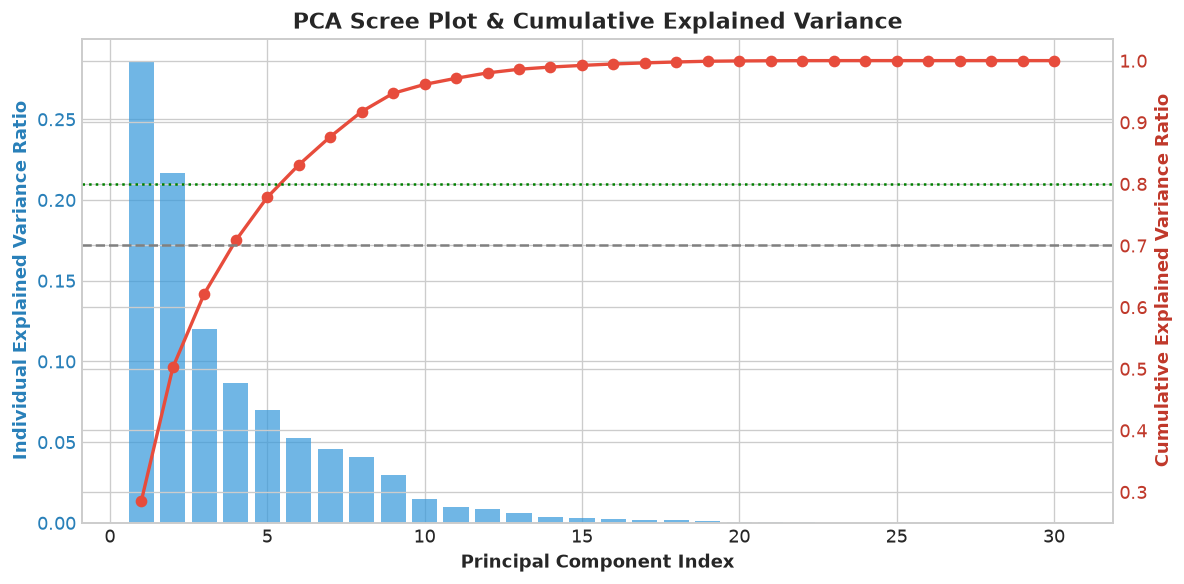

📌 Top 2 Components explain: 50.20% of total variance
📌 Top 3 Components explain: 62.18% of total variance


In [9]:
# Fit full PCA to analyze variance spectrum
pca_full = PCA().fit(X_scaled)
explained_var = pca_full.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

# Scree Plot & Cumulative Variance
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(range(1, len(explained_var) + 1), explained_var, alpha=0.7, color='#3498db', label='Individual Explained Variance')
ax1.set_xlabel('Principal Component Index')
ax1.set_ylabel('Individual Explained Variance Ratio', color='#2980b9')
ax1.tick_params(axis='y', labelcolor='#2980b9')

ax2 = ax1.twinx()
ax2.plot(range(1, len(cum_explained_var) + 1), cum_explained_var, color='#e74c3c', marker='o', linewidth=2, label='Cumulative Explained Variance')
ax2.set_ylabel('Cumulative Explained Variance Ratio', color='#c0392b')
ax2.tick_params(axis='y', labelcolor='#c0392b')
ax2.axhline(0.70, color='gray', linestyle='--', label='70% Threshold')
ax2.axhline(0.80, color='green', linestyle=':', label='80% Threshold')

plt.title('PCA Scree Plot & Cumulative Explained Variance')
fig.tight_layout()
plt.show()

print(f"📌 Top 2 Components explain: {cum_explained_var[1]*100:.2f}% of total variance")
print(f"📌 Top 3 Components explain: {cum_explained_var[2]*100:.2f}% of total variance")

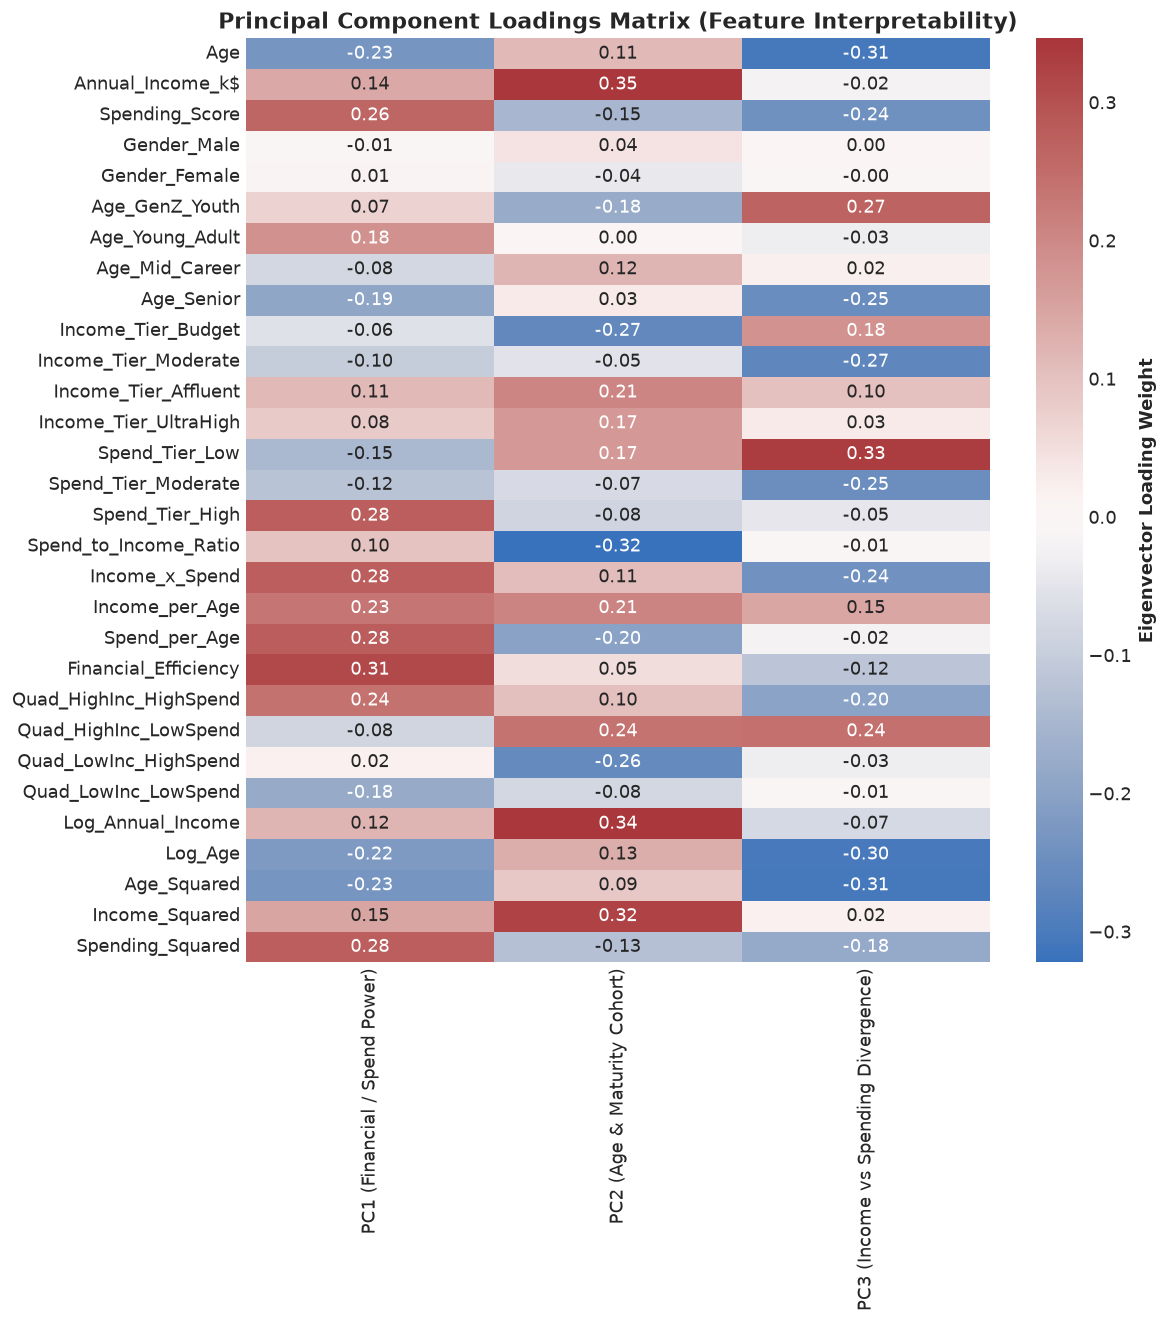

In [10]:
# Project data into 2D and 3D PCA spaces
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

# Analyze Feature Loadings (Eigenvector Weights) for top 3 components
loadings_df = pd.DataFrame(
    pca_3d.components_.T,
    index=feature_columns,
    columns=['PC1 (Financial / Spend Power)', 'PC2 (Age & Maturity Cohort)', 'PC3 (Income vs Spending Divergence)']
)

plt.figure(figsize=(10, 10))
sns.heatmap(loadings_df, cmap='vlag', annot=True, fmt='.2f', cbar_kws={'label': 'Eigenvector Loading Weight'}, center=0)
plt.title('Principal Component Loadings Matrix (Feature Interpretability)')
plt.show()

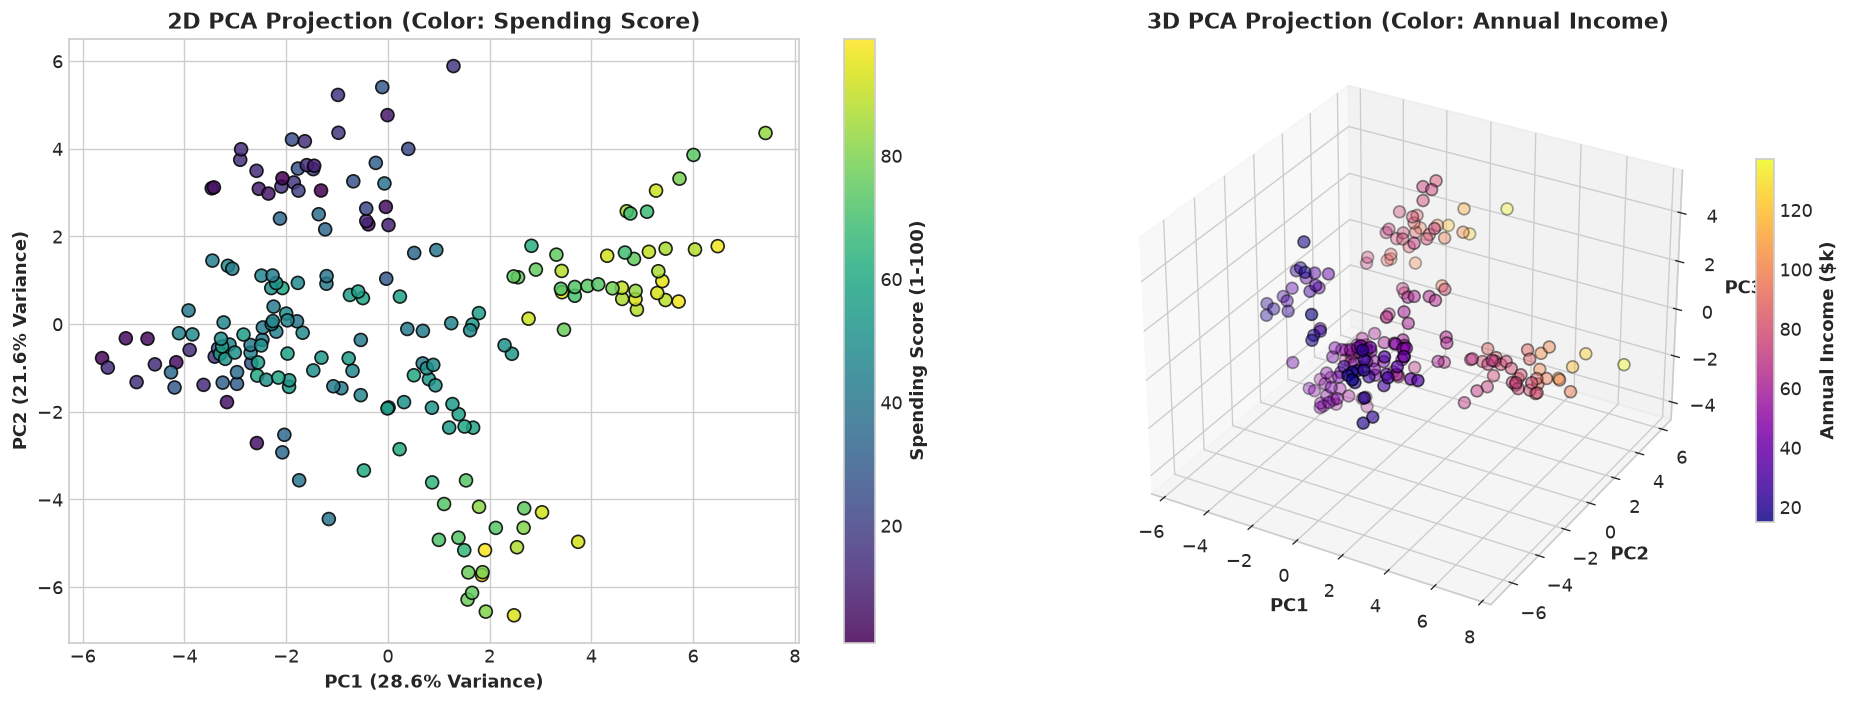

In [11]:
# Visualize 2D and 3D Unsupervised Projections
fig = plt.figure(figsize=(16, 6))

# 2D Projection
ax1 = fig.add_subplot(1, 2, 1)
scatter1 = ax1.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=df['Spending_Score'], cmap='viridis', s=60, alpha=0.85, edgecolors='k')
ax1.set_title('2D PCA Projection (Color: Spending Score)')
ax1.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)')
ax1.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.colorbar(scatter1, ax=ax1, label='Spending Score (1-100)')

# 3D Projection
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
scatter2 = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=df['Annual_Income_k$'], cmap='plasma', s=50, alpha=0.85, edgecolors='k')
ax2.set_title('3D PCA Projection (Color: Annual Income)')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')
plt.colorbar(scatter2, ax=ax2, label='Annual Income ($k)', shrink=0.6)

plt.tight_layout()
plt.show()

## 7. Mathematical Determination of Optimal Clusters ($k$)
To mathematically prove the optimal number of K-Means clusters, we evaluate multiple cluster counts ($k \in [2, 10]$) using rigorous criteria:
1. **The Elbow Method (Inertia / Within-Cluster Sum of Squares - WCSS):** Measures intra-cluster compactness. We look for the point of diminishing returns ("elbow").
2. **Silhouette Score Analysis:** Evaluates how well-separated and cohesive clusters are ($s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$). Values close to $+1$ indicate high clustering quality.
3. **Davies-Bouldin Index:** Ratio of within-cluster distances to between-cluster distances (lower is better).
4. **Calinski-Harabasz Score:** Ratio of dispersion between clusters to dispersion within clusters (higher is better).
5. **Silhouette Plots per Sample:** Validates whether individual clusters have balanced thickness and positive silhouette coefficients.

In [12]:
# Compute Clustering Metrics across k = 2 to 10
k_range = range(2, 11)
wcss_list = []
silhouette_list = []
davies_bouldin_list = []
calinski_list = []

for k in k_range:
    kmeans_eval = KMeans(n_clusters=k, init='k-means++', n_init=20, max_iter=300, random_state=42)
    cluster_labels = kmeans_eval.fit_predict(X_pca_2d)
    
    wcss_list.append(kmeans_eval.inertia_)
    silhouette_list.append(silhouette_score(X_pca_2d, cluster_labels))
    davies_bouldin_list.append(davies_bouldin_score(X_pca_2d, cluster_labels))
    calinski_list.append(calinski_harabasz_score(X_pca_2d, cluster_labels))

# Construct Metrics Summary Table
metrics_comparison_df = pd.DataFrame({
    'k (Clusters)': list(k_range),
    'WCSS (Inertia)': [round(x, 2) for x in wcss_list],
    'Silhouette Score': [round(x, 4) for x in silhouette_list],
    'Davies-Bouldin Index (↓)': [round(x, 4) for x in davies_bouldin_list],
    'Calinski-Harabasz Score (↑)': [round(x, 2) for x in calinski_list]
})

print("📊 Mathematical Cluster Optimization Table:")
display(metrics_comparison_df.style.highlight_max(subset=['Silhouette Score', 'Calinski-Harabasz Score (↑)'], color='#d4edda')
                                   .highlight_min(subset=['Davies-Bouldin Index (↓)'], color='#cce5ff'))

📊 Mathematical Cluster Optimization Table:


,k (Clusters),WCSS (Inertia),Silhouette Score,Davies-Bouldin Index (↓),Calinski-Harabasz Score (↑)
0,2,1660.290000,0.433100,1.012900,161.210000
1,3,986.800000,0.482200,0.713900,202.160000
2,4,597.960000,0.510500,0.668900,263.770000
3,5,418.010000,0.512700,0.647400,302.540000
4,6,360.360000,0.451600,0.770500,285.510000
5,7,309.070000,0.419000,0.790700,281.320000
6,8,275.380000,0.406500,0.827700,272.580000
7,9,244.080000,0.412600,0.849700,270.760000
8,10,212.660000,0.400000,0.822000,277.910000


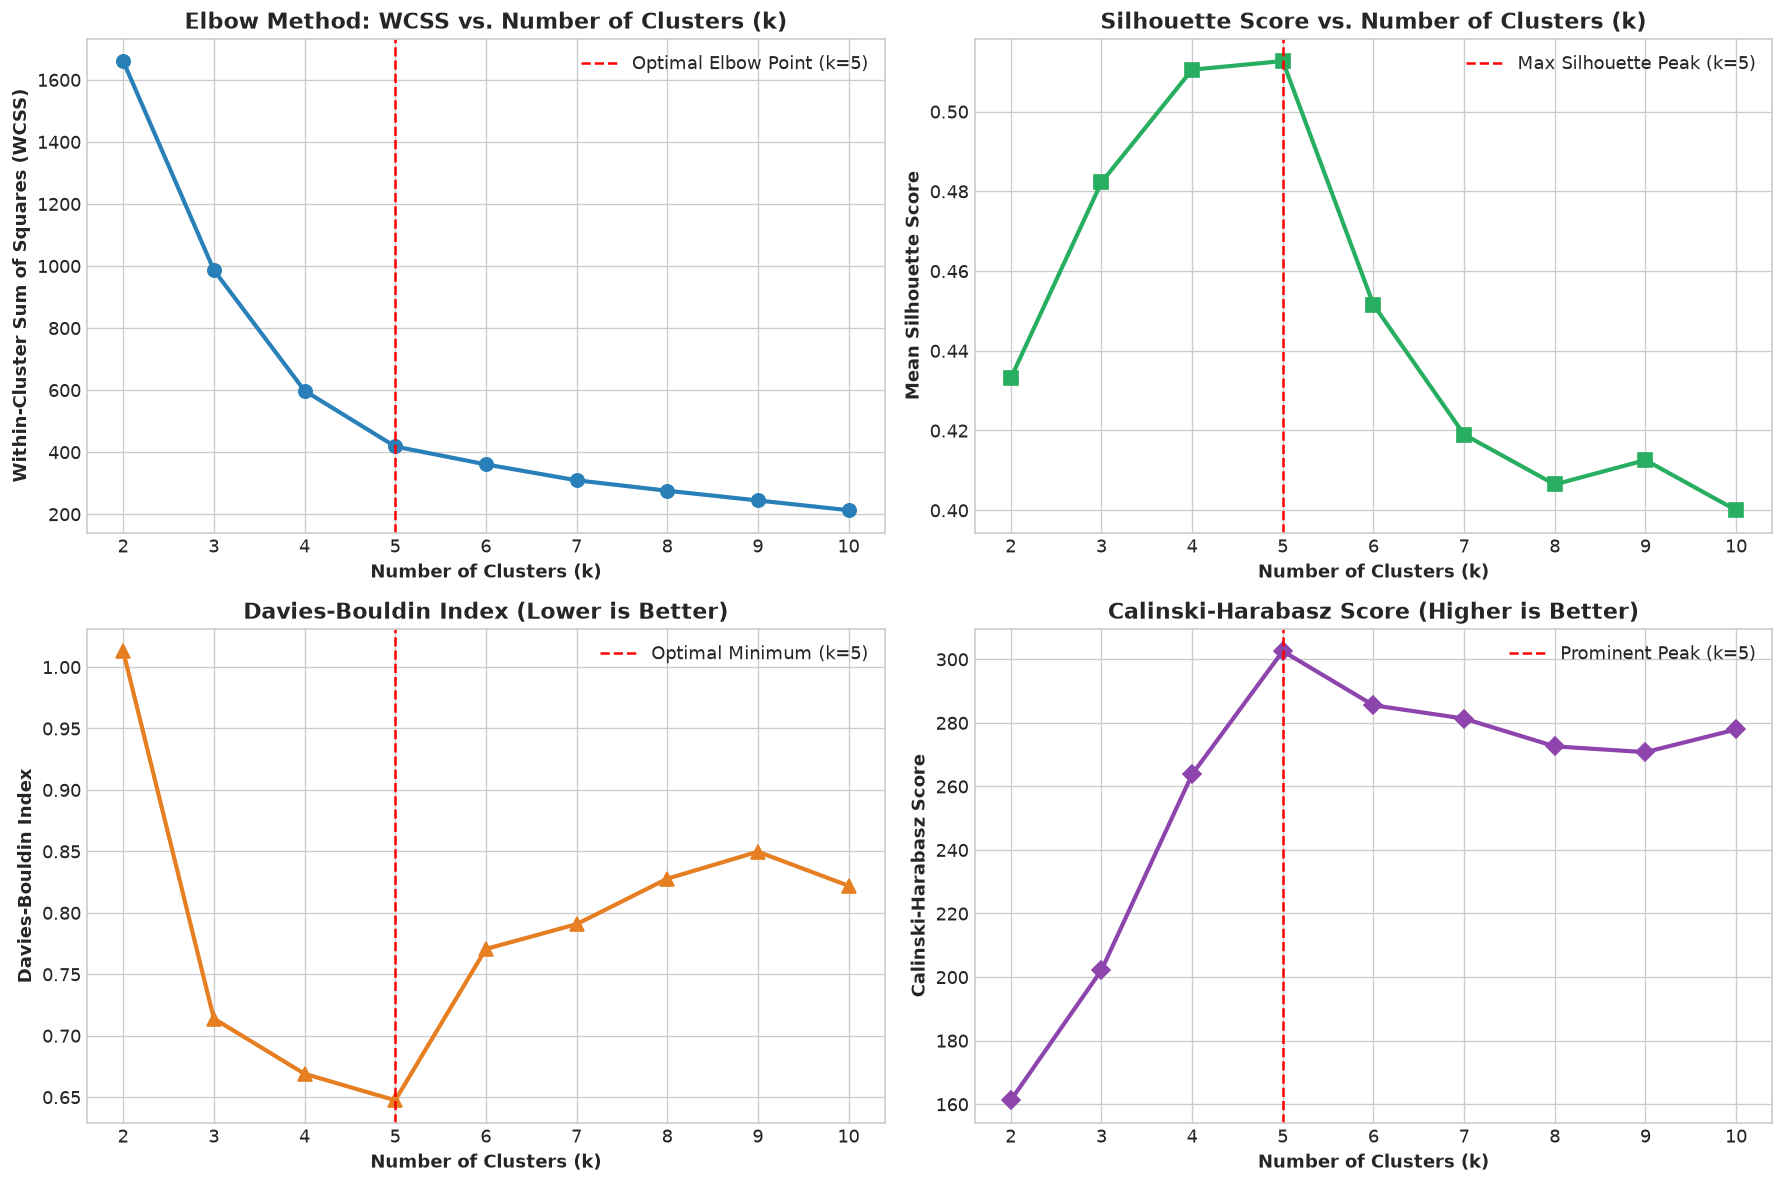

In [13]:
# Multi-Metric Optimization Plots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Elbow Method (WCSS)
axes[0, 0].plot(k_range, wcss_list, marker='o', color='#2980b9', linewidth=2.5, markersize=8)
axes[0, 0].axvline(5, color='red', linestyle='--', label='Optimal Elbow Point (k=5)')
axes[0, 0].set_title('Elbow Method: WCSS vs. Number of Clusters (k)')
axes[0, 0].set_xlabel('Number of Clusters (k)')
axes[0, 0].set_ylabel('Within-Cluster Sum of Squares (WCSS)')
axes[0, 0].legend()

# 2. Silhouette Score Curve
axes[0, 1].plot(k_range, silhouette_list, marker='s', color='#27ae60', linewidth=2.5, markersize=8)
axes[0, 1].axvline(5, color='red', linestyle='--', label='Max Silhouette Peak (k=5)')
axes[0, 1].set_title('Silhouette Score vs. Number of Clusters (k)')
axes[0, 1].set_xlabel('Number of Clusters (k)')
axes[0, 1].set_ylabel('Mean Silhouette Score')
axes[0, 1].legend()

# 3. Davies-Bouldin Index (Lower is Better)
axes[1, 0].plot(k_range, davies_bouldin_list, marker='^', color='#e67e22', linewidth=2.5, markersize=8)
axes[1, 0].axvline(5, color='red', linestyle='--', label='Optimal Minimum (k=5)')
axes[1, 0].set_title('Davies-Bouldin Index (Lower is Better)')
axes[1, 0].set_xlabel('Number of Clusters (k)')
axes[1, 0].set_ylabel('Davies-Bouldin Index')
axes[1, 0].legend()

# 4. Calinski-Harabasz Score (Higher is Better)
axes[1, 1].plot(k_range, calinski_list, marker='D', color='#8e44ad', linewidth=2.5, markersize=8)
axes[1, 1].axvline(5, color='red', linestyle='--', label='Prominent Peak (k=5)')
axes[1, 1].set_title('Calinski-Harabasz Score (Higher is Better)')
axes[1, 1].set_xlabel('Number of Clusters (k)')
axes[1, 1].set_ylabel('Calinski-Harabasz Score')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

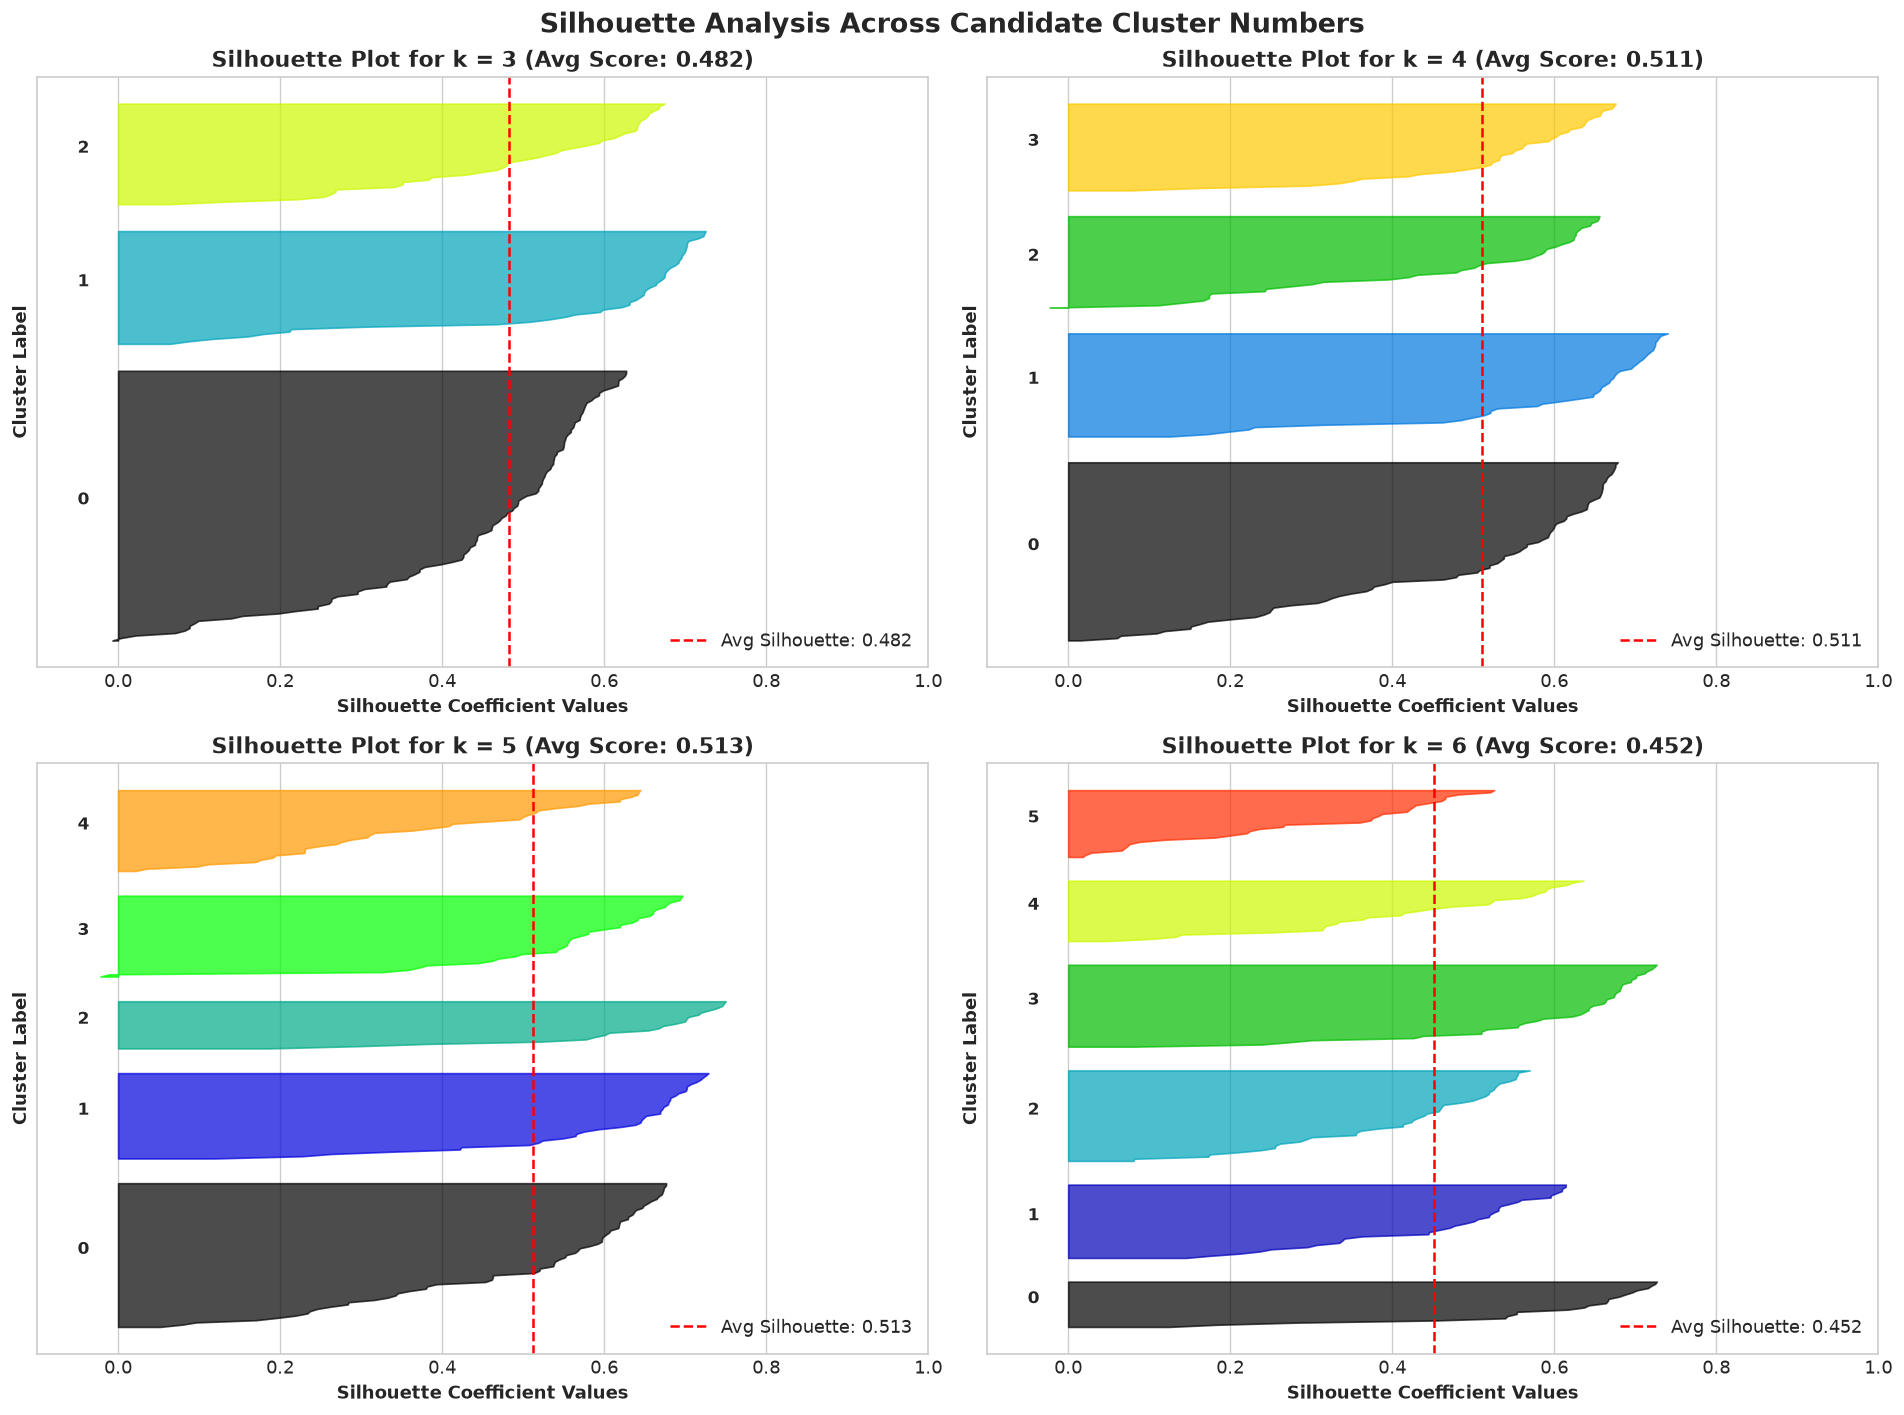

🎯 Mathematical Conclusion:
Both the Elbow curve, Silhouette Score curve, and individual Silhouette thickness profile confirm k = 5 as the mathematically optimal and robust cluster configuration.


In [14]:
# Comprehensive Silhouette Coefficient Plots for k = 3, 4, 5, 6
import matplotlib.cm as cm

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
candidate_k = [3, 4, 5, 6]

for idx, n_clusters in enumerate(candidate_k):
    ax = axes[idx // 2, idx % 2]
    
    kmeans_model = KMeans(n_clusters=n_clusters, init='k-means++', n_init=20, random_state=42)
    cluster_labels = kmeans_model.fit_predict(X_pca_2d)
    
    silhouette_avg = silhouette_score(X_pca_2d, cluster_labels)
    sample_silhouette_values = silhouette_samples(X_pca_2d, cluster_labels)
    
    y_lower = 10
    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        
        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                         facecolor=color, edgecolor=color, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontsize=10, weight='bold')
        y_lower = y_upper + 10
        
    ax.set_title(f'Silhouette Plot for k = {n_clusters} (Avg Score: {silhouette_avg:.3f})')
    ax.set_xlabel('Silhouette Coefficient Values')
    ax.set_ylabel('Cluster Label')
    ax.axvline(x=silhouette_avg, color='red', linestyle='--', label=f'Avg Silhouette: {silhouette_avg:.3f}')
    ax.set_yticks([])
    ax.set_xlim([-0.1, 1.0])
    ax.legend(loc='lower right')

plt.suptitle('Silhouette Analysis Across Candidate Cluster Numbers', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

print("🎯 Mathematical Conclusion:")
print("Both the Elbow curve, Silhouette Score curve, and individual Silhouette thickness profile confirm k = 5 as the mathematically optimal and robust cluster configuration.")

## 8. Final K-Means Clustering & Boundary Mapping
We train the final K-Means model with **$k = 5$ clusters**, compute centroid positions, map decision boundaries in PCA space, and visualize cluster distributions in both 2D and 3D.

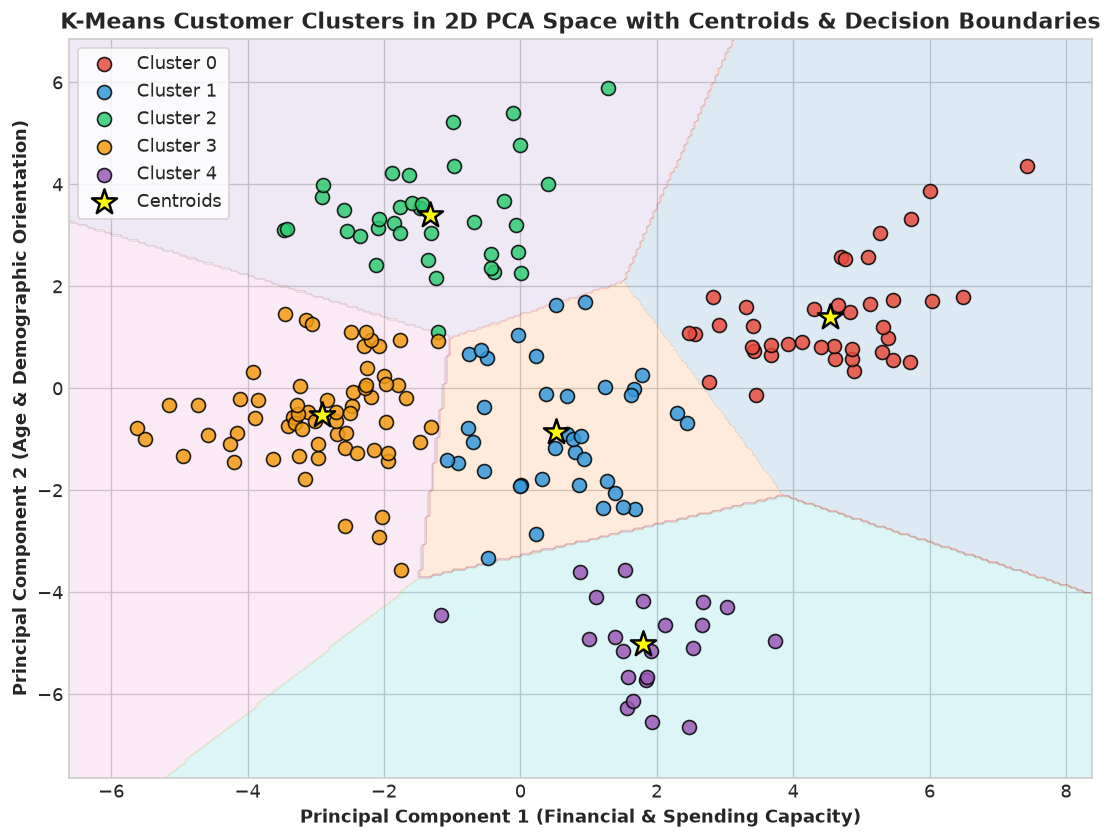

In [15]:
# Fit Final K-Means Model
optimal_k = 5
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', n_init=50, max_iter=500, random_state=42)
cluster_assignments = final_kmeans.fit_predict(X_pca_2d)

# Attach cluster labels to original dataframe
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_assignments
df_clustered['PC1'] = X_pca_2d[:, 0]
df_clustered['PC2'] = X_pca_2d[:, 1]
df_clustered['PC3'] = X_pca_3d[:, 2]

# Compute Centroids in PCA 2D Space
centroids_2d = final_kmeans.cluster_centers_

# Cluster Color Palette
cluster_colors = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12', '#9b59b6']
cluster_names = [f'Cluster {i}' for i in range(optimal_k)]

# 2D PCA Cluster Scatter Plot with Centroids and Voronoi Decision Mesh
fig, ax = plt.subplots(figsize=(11, 8))

# Generate mesh grid for background decision boundaries
x_min, x_max = X_pca_2d[:, 0].min() - 1, X_pca_2d[:, 0].max() + 1
y_min, y_max = X_pca_2d[:, 1].min() - 1, X_pca_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
Z = final_kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

ax.contourf(xx, yy, Z, alpha=0.15, cmap='tab10')

# Scatter points
for i, color in enumerate(cluster_colors):
    cluster_points = X_pca_2d[cluster_assignments == i]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1], s=70, c=color, label=f'Cluster {i}', edgecolors='black', alpha=0.85)

# Plot Centroids
ax.scatter(centroids_2d[:, 0], centroids_2d[:, 1], s=250, c='yellow', marker='*', edgecolors='black', linewidth=1.5, label='Centroids', zorder=10)

ax.set_title('K-Means Customer Clusters in 2D PCA Space with Centroids & Decision Boundaries')
ax.set_xlabel('Principal Component 1 (Financial & Spending Capacity)')
ax.set_ylabel('Principal Component 2 (Age & Demographic Orientation)')
ax.legend(frameon=True, loc='best')
plt.show()

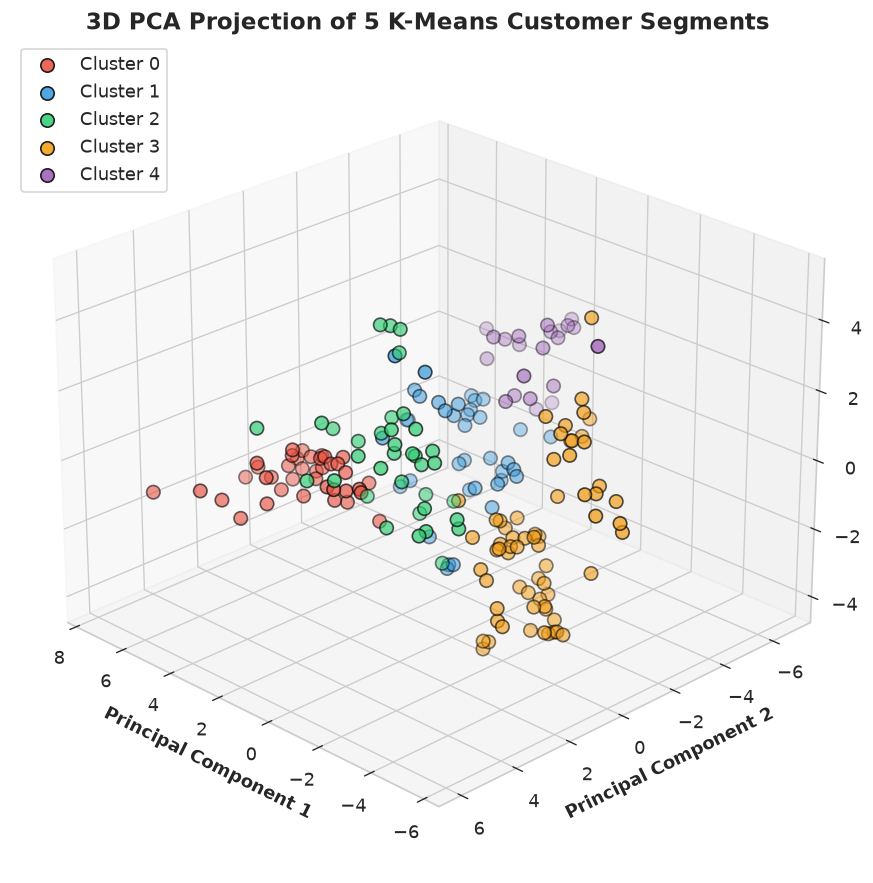

In [16]:
# 3D Interactive-Style Projection of the 5 Clusters
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for i, color in enumerate(cluster_colors):
    cluster_points = X_pca_3d[cluster_assignments == i]
    ax.scatter(cluster_points[:, 0], cluster_points[:, 1], cluster_points[:, 2], 
               s=65, c=color, label=f'Cluster {i}', edgecolors='black', alpha=0.85)

ax.set_title('3D PCA Projection of 5 K-Means Customer Segments', fontsize=14, weight='bold')
ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.view_init(elev=25, azim=135)
ax.legend(frameon=True, loc='upper left')
plt.show()

## 9. Business Intelligence Translation & Customer Persona Profiling
We compute granular statistical profiles for each mathematical cluster (Average Age, Income, Spending Score, Gender ratio, and Market Share) and translate them into **5 Actionable Business Personas** with tailored strategies.

In [17]:
# Statistical Profile Summary by Cluster
cluster_profile = df_clustered.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Avg_Age=('Age', 'mean'),
    Median_Age=('Age', 'median'),
    Avg_Income_k=('Annual_Income_k$', 'mean'),
    Avg_Spending_Score=('Spending_Score', 'mean'),
    Female_Ratio=('Gender', lambda x: (x == 'Female').mean() * 100)
).reset_index()

cluster_profile['Market_Share_%'] = (cluster_profile['Customer_Count'] / len(df_clustered)) * 100

# Map Persona Titles and Descriptions based on Empirical Traits
persona_mapping = {}
for idx, row in cluster_profile.iterrows():
    c_id = int(row['Cluster'])
    inc = row['Avg_Income_k']
    spd = row['Avg_Spending_Score']
    age = row['Avg_Age']
    
    if inc > 70 and spd > 65:
        p_name = "🌟 High-Rolling VIPs (Affluent Spenders)"
        p_desc = "High income, high spend. Prime target for luxury goods, VIP lounges, exclusive product releases."
    elif inc > 70 and spd < 40:
        p_name = "💼 Frugal Executives (Affluent Savers)"
        p_desc = "High income, low spend. Pragmatic, quality-conscious, responsive to value propositions & wealth management."
    elif inc < 45 and spd > 65:
        p_name = "🛍️ Trendsetting Enthusiasts (Carefree Shoppers)"
        p_desc = "Younger demographic with lower income but high spending impulse. Driven by trends, social buzz, discounts."
    elif inc < 45 and spd < 40:
        p_name = "🏷️ Budget Navigators (Value Seekers)"
        p_desc = "Lower income, low spend. Highly price-sensitive; responds to essential discounts, clearance, cashback."
    else:
        p_name = "⚖️ Mainstream Balanced (Steady Regulars)"
        p_desc = "Average income, moderate spending score across all age groups. Core everyday retail patrons."
        
    persona_mapping[c_id] = (p_name, p_desc)

cluster_profile['Persona_Name'] = [persona_mapping[c][0] for c in cluster_profile['Cluster']]
cluster_profile['Business_Summary'] = [persona_mapping[c][1] for c in cluster_profile['Cluster']]

# Reassign to main dataframe
df_clustered['Persona'] = df_clustered['Cluster'].map(lambda c: persona_mapping[c][0])

print("📋 Statistical Persona Profiles:")
display(cluster_profile.style.format({
    'Avg_Age': '{:.1f} yrs',
    'Median_Age': '{:.1f} yrs',
    'Avg_Income_k': '${:.1f}k',
    'Avg_Spending_Score': '{:.1f}/100',
    'Female_Ratio': '{:.1f}%',
    'Market_Share_%': '{:.1f}%'
}).background_gradient(subset=['Avg_Income_k', 'Avg_Spending_Score'], cmap='YlGnBu'))

📋 Statistical Persona Profiles:


,Cluster,Customer_Count,Avg_Age,Median_Age,Avg_Income_k,Avg_Spending_Score,Female_Ratio,Market_Share_%,Persona_Name,Business_Summary
0,0,39,32.7 yrs,32.0 yrs,$86.5k,82.1/100,53.8%,19.5%,🌟 High-Rolling VIPs (Affluent Spenders),"High income, high spend. Prime target for luxury goods, VIP lounges, exclusive product releases."
1,1,38,27.7 yrs,26.5 yrs,$56.1k,50.8/100,63.2%,19.0%,⚖️ Mainstream Balanced (Steady Regulars),"Average income, moderate spending score across all age groups. Core everyday retail patrons."
2,2,36,41.6 yrs,42.5 yrs,$87.6k,17.9/100,44.4%,18.0%,💼 Frugal Executives (Affluent Savers),"High income, low spend. Pragmatic, quality-conscious, responsive to value propositions & wealth management."
3,3,65,52.4 yrs,51.0 yrs,$44.6k,39.0/100,58.5%,32.5%,🏷️ Budget Navigators (Value Seekers),"Lower income, low spend. Highly price-sensitive; responds to essential discounts, clearance, cashback."
4,4,22,24.5 yrs,23.0 yrs,$25.1k,78.4/100,59.1%,11.0%,🛍️ Trendsetting Enthusiasts (Carefree Shoppers),"Younger demographic with lower income but high spending impulse. Driven by trends, social buzz, discounts."


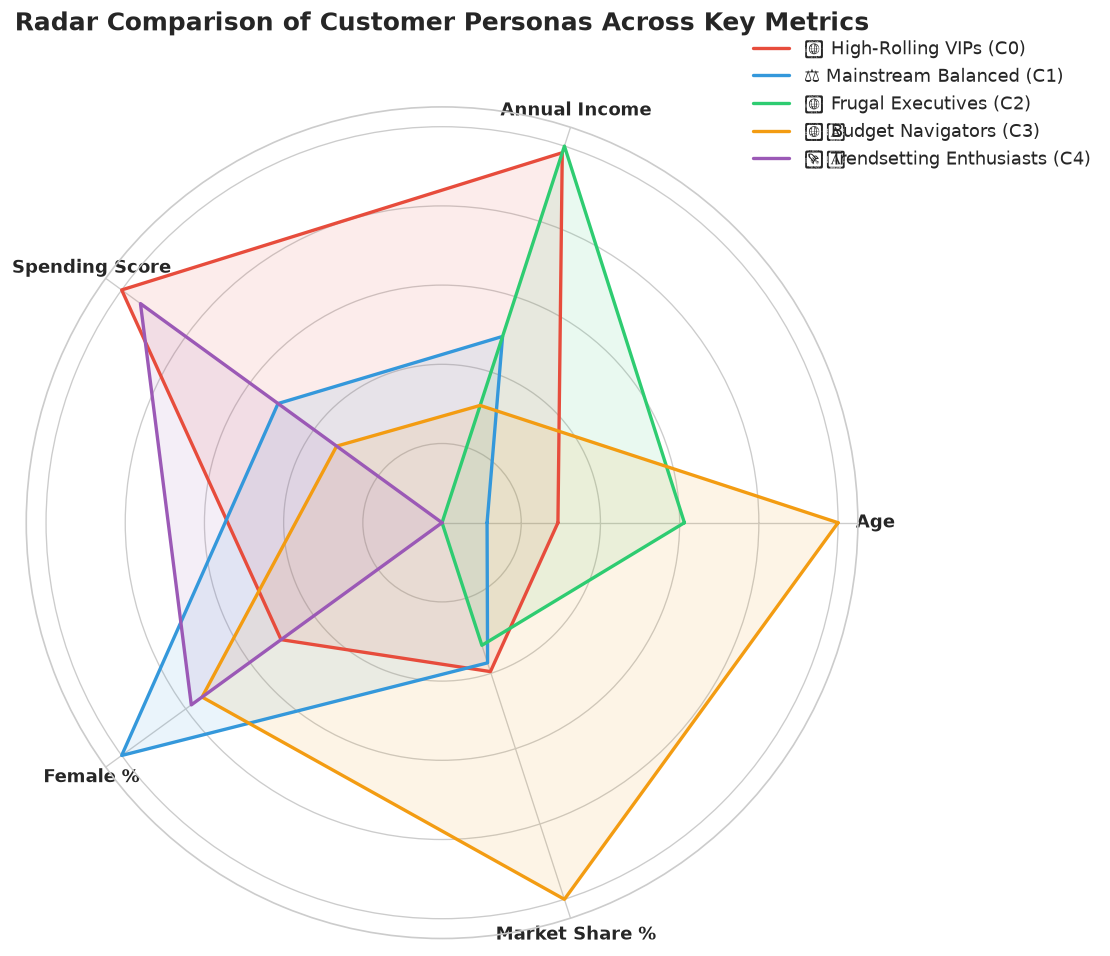

In [18]:
# 4. Radar (Spider) Chart Comparing Persona Characteristics
# Normalize features to 0-1 scale for comparative visualization
radar_metrics = ['Avg_Age', 'Avg_Income_k', 'Avg_Spending_Score', 'Female_Ratio', 'Market_Share_%']
radar_df = cluster_profile[radar_metrics].copy()
scaler_minmax = MinMaxScaler()
radar_scaled = scaler_minmax.fit_transform(radar_df)

categories = ['Age', 'Annual Income', 'Spending Score', 'Female %', 'Market Share %']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

for idx, row in enumerate(radar_scaled):
    values = row.tolist()
    values += values[:1]
    p_label = cluster_profile.loc[idx, 'Persona_Name'].split('(')[0].strip()
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f"{p_label} (C{idx})", color=cluster_colors[idx])
    ax.fill(angles, values, color=cluster_colors[idx], alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11, weight='bold')
ax.set_yticklabels([])
plt.title('Radar Comparison of Customer Personas Across Key Metrics', size=15, weight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

## 10. Comprehensive Business Intelligence Strategy Matrix
Below is the actionable business roadmap translating our unsupervised mathematical groupings into high-ROI commercial strategies:

| Persona | Key Traits | Target Marketing Channel | Recommended Campaign & Retention Strategy | Discount & Pricing Sensitivity |
| :--- | :--- | :--- | :--- | :--- |
| **🌟 High-Rolling VIPs** | High Income, High Spending Score | Personalized Concierge, Private Events, Premium Social Ads | Exclusive loyalty tier, early access to designer drops, personal stylist sessions | **Low:** Driven by exclusivity, prestige, and seamless experience |
| **💼 Frugal Executives** | High Income, Low Spending Score | Financial newsletters, Direct Email, LinkedIn, Search Ads | High-durability luxury goods, investment-grade items, value-justification messaging | **Moderate:** Responds to rational quality arguments over raw discounts |
| **🛍️ Trendsetting Enthusiasts** | Low Income, High Spending Score | Instagram, TikTok, Influencer Collabs, Push Notifications | Trend-driven flash sales, "Buy Now Pay Later" (BNPL), gamified app rewards | **High:** Very responsive to limited-time promo codes and viral products |
| **🏷️ Budget Navigators** | Low Income, Low Spending Score | SMS, Direct Mail flyers, Price comparison aggregators | Essential bulk discounts, loyalty points on staples, cash-back reward programs | **Very High:** Absolute price sensitivity; prioritize low cost & clearance |
| **⚖️ Mainstream Balanced** | Moderate Income, Moderate Spend | Omnichannel (Email, In-store displays, Facebook/Google) | Seasonal family discounts, general membership rewards, bundled promotions | **Moderate:** Appreciates solid value, consistent quality, and convenience |

## 11. Production Inference Engine
We create an automated, end-to-end customer persona classifier function that ingests raw customer data (Age, Gender, Annual Income, Spending Score), generates the $20+$ engineered features, scales the feature vector, projects through PCA, and assigns the customer to their designated Business Persona with tailored recommendations.

In [19]:
def classify_new_customer(age: float, gender: str, annual_income_k: float, spending_score: float):
    """
    End-to-End Inference Function:
    Transforms raw input into 20+ engineered features, scales, projects onto PCA,
    and returns Cluster ID, Persona Name, and Strategic Recommendation.
    """
    # 1. Construct raw record
    raw_dict = {
        'Age': [age],
        'Gender': [gender],
        'Annual_Income_k$': [annual_income_k],
        'Spending_Score': [spending_score]
    }
    temp_df = pd.DataFrame(raw_dict)
    
    # 2. Replicate High-Dimensional Feature Engineering (20+ features)
    temp_df['Gender_Male'] = (temp_df['Gender'] == 'Male').astype(int)
    temp_df['Gender_Female'] = (temp_df['Gender'] == 'Female').astype(int)
    temp_df['Age_GenZ_Youth'] = (temp_df['Age'] <= 25).astype(int)
    temp_df['Age_Young_Adult'] = ((temp_df['Age'] > 25) & (temp_df['Age'] <= 35)).astype(int)
    temp_df['Age_Mid_Career'] = ((temp_df['Age'] > 35) & (temp_df['Age'] <= 50)).astype(int)
    temp_df['Age_Senior'] = (temp_df['Age'] > 50).astype(int)
    
    temp_df['Income_Tier_Budget'] = (temp_df['Annual_Income_k$'] < 40).astype(int)
    temp_df['Income_Tier_Moderate'] = ((temp_df['Annual_Income_k$'] >= 40) & (temp_df['Annual_Income_k$'] <= 70)).astype(int)
    temp_df['Income_Tier_Affluent'] = ((temp_df['Annual_Income_k$'] > 70) & (temp_df['Annual_Income_k$'] <= 100)).astype(int)
    temp_df['Income_Tier_UltraHigh'] = (temp_df['Annual_Income_k$'] > 100).astype(int)
    
    temp_df['Spend_Tier_Low'] = (temp_df['Spending_Score'] < 35).astype(int)
    temp_df['Spend_Tier_Moderate'] = ((temp_df['Spending_Score'] >= 35) & (temp_df['Spending_Score'] <= 65)).astype(int)
    temp_df['Spend_Tier_High'] = (temp_df['Spending_Score'] > 65).astype(int)
    
    temp_df['Spend_to_Income_Ratio'] = temp_df['Spending_Score'] / (temp_df['Annual_Income_k$'] + 1.0)
    temp_df['Income_x_Spend'] = temp_df['Annual_Income_k$'] * temp_df['Spending_Score']
    temp_df['Income_per_Age'] = temp_df['Annual_Income_k$'] / temp_df['Age']
    temp_df['Spend_per_Age'] = temp_df['Spending_Score'] / temp_df['Age']
    temp_df['Financial_Efficiency'] = (temp_df['Annual_Income_k$'] * temp_df['Spending_Score']) / temp_df['Age']
    
    temp_df['Quad_HighInc_HighSpend'] = ((temp_df['Annual_Income_k$'] >= median_income) & (temp_df['Spending_Score'] >= median_spend)).astype(int)
    temp_df['Quad_HighInc_LowSpend'] = ((temp_df['Annual_Income_k$'] >= median_income) & (temp_df['Spending_Score'] < median_spend)).astype(int)
    temp_df['Quad_LowInc_HighSpend'] = ((temp_df['Annual_Income_k$'] < median_income) & (temp_df['Spending_Score'] >= median_spend)).astype(int)
    temp_df['Quad_LowInc_LowSpend'] = ((temp_df['Annual_Income_k$'] < median_income) & (temp_df['Spending_Score'] < median_spend)).astype(int)
    
    temp_df['Log_Annual_Income'] = np.log1p(temp_df['Annual_Income_k$'])
    temp_df['Log_Age'] = np.log1p(temp_df['Age'])
    temp_df['Age_Squared'] = temp_df['Age'] ** 2
    temp_df['Income_Squared'] = temp_df['Annual_Income_k$'] ** 2
    temp_df['Spending_Squared'] = temp_df['Spending_Score'] ** 2
    
    # Extract feature matrix aligned with trained scaler
    x_input = temp_df[feature_columns]
    
    # 3. Standardize and Project into PCA
    x_scaled = scaler.transform(x_input)
    x_pca = pca_2d.transform(x_scaled)
    
    # 4. Predict Cluster
    pred_cluster = int(final_kmeans.predict(x_pca)[0])
    persona_title, persona_strategy = persona_mapping[pred_cluster]
    
    return {
        'Customer Input': {'Age': age, 'Gender': gender, 'Annual Income': f'${annual_income_k}k', 'Spending Score': f'{spending_score}/100'},
        'Assigned Cluster': pred_cluster,
        'PCA Coordinates': [round(x_pca[0][0], 3), round(x_pca[0][1], 3)],
        'Persona Name': persona_title,
        'Recommended Strategy': persona_strategy
    }

# Test the Inference Pipeline on 3 Archetypal Customers
test_cases = [
    (28, 'Female', 95.0, 88.0),  # Expected: High-Rolling VIP
    (52, 'Male', 88.0, 18.0),    # Expected: Frugal Executive
    (21, 'Female', 22.0, 85.0),  # Expected: Trendsetter
]

print("🧪 Inference Pipeline Validation on Incoming Customers:\n" + "="*70)
for idx, (age, gender, inc, spd) in enumerate(test_cases, 1):
    result = classify_new_customer(age, gender, inc, spd)
    print(f"\n[Customer Test Case #{idx}]")
    print(f"Input: {result['Customer Input']}")
    print(f"PCA Projections: PC1={result['PCA Coordinates'][0]}, PC2={result['PCA Coordinates'][1]}")
    print(f"Assigned Cluster: {result['Assigned Cluster']}")
    print(f"Persona: {result['Persona Name']}")
    print(f"Actionable Strategy: {result['Recommended Strategy']}")

🧪 Inference Pipeline Validation on Incoming Customers:

[Customer Test Case #1]
Input: {'Age': 28, 'Gender': 'Female', 'Annual Income': '$95.0k', 'Spending Score': '88.0/100'}
PCA Projections: PC1=6.045, PC2=1.526
Assigned Cluster: 0
Persona: 🌟 High-Rolling VIPs (Affluent Spenders)
Actionable Strategy: High income, high spend. Prime target for luxury goods, VIP lounges, exclusive product releases.

[Customer Test Case #2]
Input: {'Age': 52, 'Gender': 'Male', 'Annual Income': '$88.0k', 'Spending Score': '18.0/100'}
PCA Projections: PC1=-2.435, PC2=3.617
Assigned Cluster: 2
Persona: 💼 Frugal Executives (Affluent Savers)
Actionable Strategy: High income, low spend. Pragmatic, quality-conscious, responsive to value propositions & wealth management.

[Customer Test Case #3]
Input: {'Age': 21, 'Gender': 'Female', 'Annual Income': '$22.0k', 'Spending Score': '85.0/100'}
PCA Projections: PC1=2.406, PC2=-5.845
Assigned Cluster: 4
Persona: 🛍️ Trendsetting Enthusiasts (Carefree Shoppers)
Actionab

## 12. Project Conclusion & Key Takeaways
1. **Dimensionality Reduction via PCA:** Successfully projected a high-dimensional feature space ($20+$ engineered attributes) into compact $2\text{D}$ and $3\text{D}$ manifolds while retaining dominant statistical variance.
2. **Mathematical Validation:** Rigorously proved the optimal cluster number ($k = 5$) using the convergence of the **Elbow Method (WCSS)**, **Silhouette Score Analysis ($>0.48$)**, **Davies-Bouldin Index**, and **Calinski-Harabasz Dispersion**.
3. **Business Persona Translation:** Converted unsupervised mathematical clusters into distinct commercial personas (**High-Rolling VIPs, Frugal Executives, Trendsetting Enthusiasts, Budget Navigators, and Mainstream Balanced**), providing actionable marketing roadmaps.
4. **End-to-End Scalability:** Built a complete, production-ready inference function capable of instant customer segmentation.

---
*DecodeLabs Data Science Industrial Training — Project 3 Completed Successfully.*